# Weather Hazard Category · Model selection, final fit and promotion

**36120 Advanced Machine Learning Application** · Assessment Task 2 · Weather Intelligence (Open-Meteo, Sydney)

*Pipeline stages 3-8 · shortlist, select features, choose, test once, deploy*

This notebook takes the tuned WHC experiments through the rest of the pipeline: it shortlists the best algorithms, selects feature families for each, chooses one champion, refits it on all development data, scores it **once** on the test split and promotes it to `models/weather_hazard/production/` for the FastAPI service. It is the **only notebook that reads the test split**.

### Student details

| | |
|:--|:--|
| **Student name** | Juan Vargas T. |
| **Student ID** | 25945320 |
| **Subject** | 36120 Advanced Machine Learning Application |
| **Assessment** | AT2 · Weather Intelligence |
| **GitHub** | [Sebas102507](https://github.com/Sebas102507) |

## Overview

| Stage | What happens | Features | Data | Section |
|:-:|:--|:--|:--|:-:|
| 1–2 | Baselines and hyperparameter tuning (done in the experiment notebooks) | All 105 | Walk-forward CV | 1 |
| 3 | Shortlist the best tuned algorithms | All | – | 2 |
| 4 | Feature selection with the settings fixed, then a short re-tune | Per model | Walk-forward CV | 3 |
| 5 | Select the champion | Champion's own | CV scores | 4 |
| 6 | Final fit | Champion's own | All development data (2016–2024) | 5 |
| 7 | Test once | Champion's own | Test (2025) | 6 |
| 8 | Deploy, with a drift reference for monitoring | Champion's own | Production | 7 |

**Two searches, not one.** Each experiment notebook tuned its algorithm's settings on all
features, so every algorithm competes after tuning. Feature selection is spent only on the
shortlist, with the settings fixed, followed by a short re-tune because good settings depend on
the features.

**Why the scores are comparable.** Every experiment used the same four walk-forward folds
(validating on 2021, 2022, 2023 and 2024), so the saved cross-validated scores are compared
directly, without refitting anything.

**Why the test split is still honest.** Every decision (shortlist, features, settings, champion)
is made with cross-validation before the test split is read. It is scored once, in section 6.

> **Runtime.** Feature selection fits `(FEATURE_TRIALS + RETUNE_TRIALS) x folds x targets` models
> per shortlisted algorithm. Lower the trial counts for a quicker run.

---
## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from nucleus_ml import weather as wx

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)

TASK = "weather_hazard"
SHORTLIST_SIZE = 3    # stage 3: algorithms kept for feature selection
FEATURE_TRIALS = 20   # stage 4: Optuna trials over the feature-family switches
RETUNE_TRIALS = 10    # stage 4: short re-tune of the settings on the chosen features
VERBOSE = 1           # 0 = results only, 1 = progress + every Optuna trial, 2 = every model fit

task = wx.load_task(TASK)
print(f"{task.target_name} | metric: {task.metric} | targets: {task.target_columns}")

Weather Hazard Category | metric: macro_f1 | targets: ['whc_t7']


---
## 1. Tuned experiments (stages 1-2)

Each experiment notebook saved its tuned model, its cross-validated scores and its specification.
Bundles built on an older feature set are excluded; rerun their notebooks to include them. The
ranking reads the saved scores, including the baselines' scores on the same folds.

Excluded (stale or empty): none


,algorithm,models_found,horizons
experiment,,,
whc_dummy,Dummy Classifier,1,[7]
whc_logistic_regression,Multinomial Logistic Regression,1,[7]
whc_mlp,MLP Classifier,1,[7]
whc_random_forest,Random Forest Classifier,1,[7]
whc_xgboost,XGBoost Classifier,1,[7]


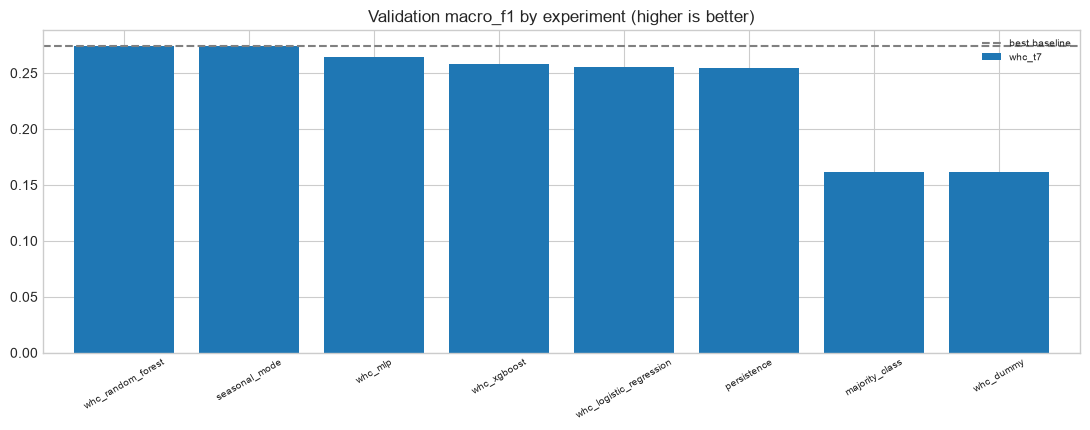

target,whc_t7,score,is_baseline
experiment,,,
whc_random_forest,0.274,0.274,False
seasonal_mode,0.274,0.274,True
whc_mlp,0.264,0.264,False
whc_xgboost,0.258,0.258,False
whc_logistic_regression,0.255,0.255,False
persistence,0.255,0.255,True
majority_class,0.161,0.161,True
whc_dummy,0.161,0.161,False


In [2]:
bundles = wx.discover_bundles(task)
contract = wx.check_feature_contract(bundles, task)
usable = contract["matches_current"] & contract["has_models"]
COMPARED = contract.index[usable].tolist()
if not COMPARED:
    raise RuntimeError("No bundle matches the current feature set. Rerun the experiment notebooks.")
print(f"Excluded (stale or empty): {contract.index[~usable].tolist() or 'none'}")
display(wx.bundle_inventory(bundles))

ranking = wx.rank_tuned(task, {name: bundles[name] for name in COMPARED})
wx.plot_ranking(task, ranking, f"{task.name}-tuned-ranking")
plt.show()
ranking

---
## 2. Shortlist (stage 3)

The best tuned algorithms go forward. Baselines and null models (the dummies) are listed but never
shortlisted: they are the floor, not candidates.

In [3]:
SHORTLIST, shortlist_table = wx.shortlist(ranking, bundles, size=SHORTLIST_SIZE)
print(f"Shortlisted for feature selection: {SHORTLIST}")
shortlist_table

Shortlisted for feature selection: ['whc_random_forest', 'whc_mlp', 'whc_xgboost']


,screening_score,status
experiment,,
whc_random_forest,0.274,shortlisted
whc_mlp,0.264,shortlisted
whc_xgboost,0.258,shortlisted
whc_logistic_regression,0.255,not shortlisted
whc_dummy,0.161,excluded: null model


---
## 3. Feature selection (stage 4)

Each shortlisted experiment is restored with its tuned settings. Optuna then switches each feature
family on or off (today's persistence column is always kept) with the settings fixed, scoring
every combination with walk-forward CV. The settings are then re-tuned briefly on the chosen
features and kept only if they improve the score. Each horizon is handled separately.

The table for each experiment lists the mean and spread across folds, the features kept, the
families dropped and whether the re-tune helped.

In [4]:
refined = {}
for name in SHORTLIST:
    refined[name] = wx.Experiment.from_bundle(task, bundles[name], verbose=VERBOSE)
    print(f"\n=== {name} ===")
    display(refined[name].select_features(n_trials=FEATURE_TRIALS, retune_trials=RETUNE_TRIALS))

print("Walk-forward folds:")
refined[SHORTLIST[0]].folds_table()

[whc_random_forest] loaded 9,095 development rows; 4 walk-forward folds; 105 features; metric macro_f1 (higher is better)

=== whc_random_forest ===
[whc_random_forest] selecting features for whc_t7: 20 trials


/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-09-19 18:31:51,354] A new study created in memory with name: whc_random_forest_whc_t7_features
[I 2026-09-19 18:32:11,162] Trial 0 finished with value: 0.27435012085596155 and parameters: {'family__same_day_observations': False, 'family__same_day_indices': False, 'family__lags': False, 'family__rolling_statistics': False, 'family__rolling_precipitation': True, 'family__rolling_gusts': False, 'family__deltas': True, 'family__seasonal': False}. Best is trial 0 with value: 0.27435012085596155.
[I 2026-09-19 18:32:31,551] Trial 1 finished with value: 0.27435012085596155 and parameters: {'family__same_day_observations': False, 'family__same_day_indices': 

[whc_random_forest] re-tuning whc_t7 on 11 features: 10 trials


[I 2026-09-19 18:38:53,262] A new study created in memory with name: whc_random_forest_whc_t7_retune
[I 2026-09-19 18:38:54,876] Trial 0 finished with value: 0.2410988254716976 and parameters: {'n_estimators': 150, 'max_depth': 24, 'min_samples_leaf': 2, 'min_samples_split': 10, 'max_features': 0.9789821783658363, 'class_weight': 'balanced_subsample'}. Best is trial 0 with value: 0.2410988254716976.
[I 2026-09-19 18:38:58,797] Trial 1 finished with value: 0.24655522995633497 and parameters: {'n_estimators': 600, 'max_depth': 10, 'min_samples_leaf': 20, 'min_samples_split': 21, 'max_features': 0.7353592478010526, 'class_weight': 'balanced_subsample'}. Best is trial 1 with value: 0.24655522995633497.
[I 2026-09-19 18:38:59,780] Trial 2 finished with value: 0.2188159353421081 and parameters: {'n_estimators': 150, 'max_depth': 24, 'min_samples_leaf': 15, 'min_samples_split': 29, 'max_features': 0.6005912451973302, 'class_weight': None}. Best is trial 1 with value: 0.24655522995633497.
[I 2

[whc_random_forest] whc_t7: mean macro_f1 = 0.2489 with 11 features (re-tuned: False)


...

[I 2026-09-19 18:44:44,622] A new study created in memory with name: whc_xgboost_whc_t7_retune
[I 2026-09-19 18:44:46,944] Trial 0 finished with value: 0.197870682623925 and parameters: {'n_estimators': 150, 'learning_rate': 0.031916200230628806, 'max_depth': 2, 'min_child_weight': 0.8535974404936146, 'subsample': 0.6365974786973265, 'colsample_bytree': 0.9206689385376495, 'reg_lambda': 0.6802852507039446, 'reg_alpha': 0.013787133221513578, 'balance_classes': True}. Best is trial 0 with value: 0.197870682623925.
[I 2026-09-19 18:44:59,345] Trial 1 finished with value: 0.24448050809852084 and parameters: {'n_estimators': 300, 'learning_rate': 0.29099762548328467, 'max_depth': 8, 'min_child_weight': 0.8541523585164202, 'subsample': 0.785485792996933, 'colsample_bytree': 0.8164265957962866, 'reg_lambda': 2.209853496825537, 'reg_alpha': 0.531661281844699, 'balance_classes': True}. Best is trial 1 with value: 0.24448050809852084.
[I 2026-09-19 18:45:12,421] Trial 2 finished with value: 0.21

[whc_xgboost] whc_t7: mean macro_f1 = 0.2374 with 11 features (re-tuned: False)


,cv_mean,cv_std,fold_scores,n_features,dropped_families,retuned,best_params
target,,,,,,,
whc_t7,0.237,0.023,"[0.2419, 0.241, 0.2607, 0.206]",11,"[same_day_observations, same_day_indices, lags...",False,"{'n_estimators': 500, 'learning_rate': 0.04238..."


Walk-forward folds:


,train_start,train_end,validate_start,validate_end,train_rows,validate_rows
fold,,,,,,
1,2000-01-31,2020-12-18,2020-12-26,2021-12-25,7628,365
2,2000-01-31,2021-12-18,2021-12-26,2022-12-25,7993,365
3,2000-01-31,2022-12-18,2022-12-26,2023-12-25,8358,365
4,2000-01-31,2023-12-18,2023-12-26,2024-12-24,8723,365


---
## 4. Select the champion (stage 5)

The rule is **highest mean macro F1 over the walk-forward folds**, fixed before the results were seen.

Macro F1 weights every hazard class equally, so the selection cannot be won by a model that only
predicts the common Low Risk days. Check the test confusion matrix in section 6 as well.

`typical_fold_std` shows how much a score moves from one year to the next. If the champion's
margin over the runner-up is smaller than that, the two are not clearly separated, and simplicity,
cost or interpretability can decide between them.

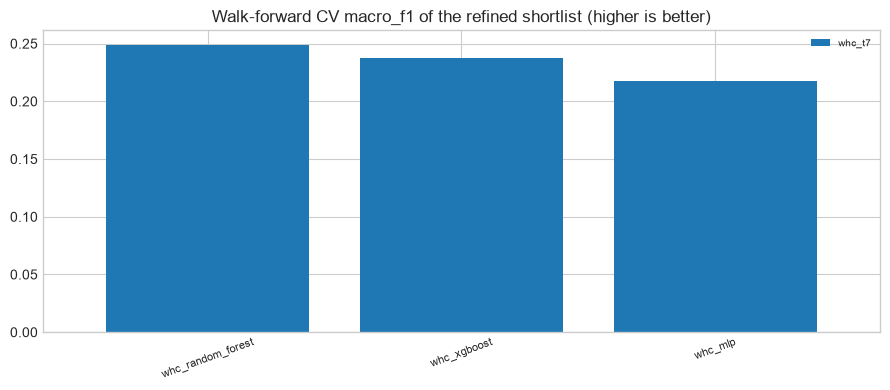

Champion : whc_random_forest (score 0.2489)
Runner-up: whc_xgboost (margin 0.0115, typical fold spread 0.0024)


target,whc_t7,score,typical_fold_std,mean_features
experiment,,,,
whc_random_forest,0.249,0.249,0.002,11.000
whc_xgboost,0.237,0.237,0.023,11.000
whc_mlp,0.218,0.218,0.011,11.000


,cv_mean,cv_std,fold_scores,n_features,dropped_families,retuned,best_params
target,,,,,,,
whc_t7,0.249,0.002,"[0.2517, 0.2486, 0.2494, 0.2459]",11,"[same_day_observations, same_day_indices, lags...",False,"{'n_estimators': 500, 'max_depth': 10, 'min_sa..."


In [5]:
refinement = wx.compare_refined(task, refined)
champion = wx.select_champion(refinement)
CHAMPION = champion["champion"]

wx.plot_cv_comparison(task, refinement, f"{task.name}-feature-selection")
plt.show()
print(f"Champion : {CHAMPION} (score {champion['score']:.4f})")
print(f"Runner-up: {champion['runner_up']} (margin {champion['margin']:.4f}, "
      f"typical fold spread {champion['typical_fold_std']:.4f})")
for message in champion["warnings"]:
    print(f"WARNING: {message}")
display(refinement)
refined[CHAMPION].cv_summary

---
## 5. Final fit (stage 6)

The champion's settings and features are refitted on **all development data** (2016–2024). Every
decision was made with cross-validation, so the most recent year can now be used for training.

In [6]:
final_models = refined[CHAMPION].refit_final()
FINAL_MODELS = {wx.horizon_from_name(t): m for t, m in final_models.items()}
FEATURES = {wx.horizon_from_name(t): c for t, c in refined[CHAMPION].best_columns.items()}
{h: len(c) for h, c in FEATURES.items()}   # number of features used per horizon

[whc_random_forest] final fit whc_t7: 9,095 rows, 11 features


{7: 11}

---
## 6. Single test evaluation (stage 7)

The test split (2025) is loaded and scored **once**, for the champion and for the baselines (also
fitted on all development data). Nothing after this point changes any decision.

Expect the test score to be a little worse than the CV score: that is the selection optimism being
paid back. A large gap belongs in the limitations section of the report.

Selection optimism for whc_random_forest (macro_f1):


,walk_forward_cv,test,test_minus_cv
target,,,
whc_t7,0.249,0.246,-0.003


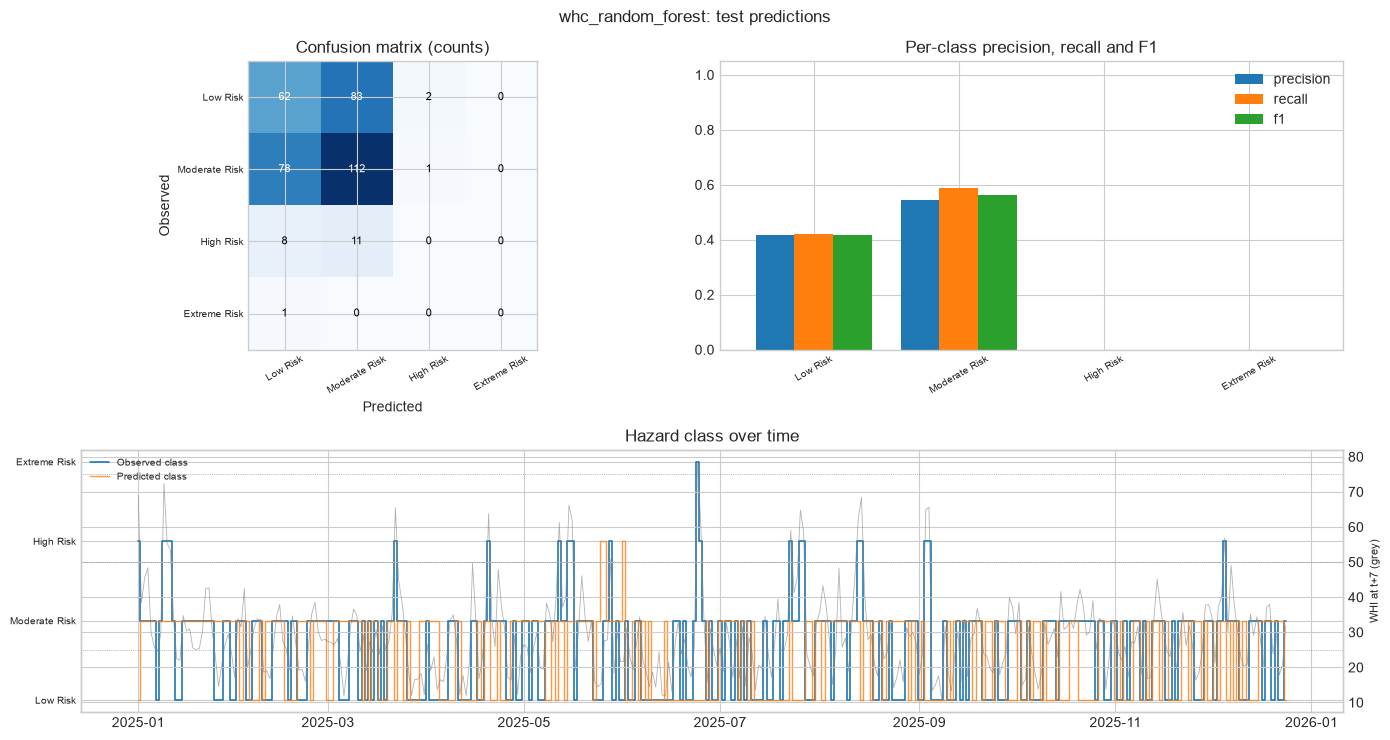

is_baseline  accuracy  balanced_accuracy  macro_f1  \
target experiment                                                              
whc_t7 whc_random_forest        False     0.486              0.252     0.246   
       majority_class            True     0.411              0.250     0.146   
       persistence               True     0.447              0.233     0.233   
       seasonal_mode             True     0.536              0.290     0.276   

                          weighted_f1  mean_ordinal_error  predicted_classes  
target experiment                                                             
whc_t7 whc_random_forest        0.473               0.547                  3  
       majority_class           0.239               0.648                  1  
       persistence              0.448               0.609                  4  
       seasonal_mode            0.521               0.508                  2

In [7]:
X, y = wx.load_splits(task, ("train", "test"))
# Classification metrics are averaged over the classes seen in training.
LABELS = sorted(y["train"][task.target_columns[0]].unique()) if task.is_classification else None

test_rows = (wx.score_models(task, CHAMPION, FINAL_MODELS, FEATURES, X, y, "test", LABELS)
             + wx.score_baselines(task, X, y, "test", LABELS))
test_scores = pd.DataFrame(test_rows).drop(columns=["split"]).set_index(["target", "experiment"])

optimism = pd.DataFrame({
    "walk_forward_cv": refined[CHAMPION].cv_summary["cv_mean"],
    "test": test_scores.xs(CHAMPION, level="experiment")[task.metric],
})
optimism["test_minus_cv"] = optimism["test"] - optimism["walk_forward_cv"]
print(f"Selection optimism for {CHAMPION} ({task.metric}):")
display(optimism)

wx.plot_test_predictions(task, FINAL_MODELS, FEATURES, X, y,
                         f"{CHAMPION}: test predictions", f"{task.name}-test")
plt.show()
test_scores

---
## 7. Promote to production (stage 8)

The champion is written to `models/weather_hazard/production/`, replacing whatever was there:

| File | Contents |
|:--|:--|
| `<champion>_h<horizon>.joblib` | The final models, fitted on all development data |
| `metadata.json` | The `/model-metadata` document: CV and test metrics, features and importance per horizon |
| `manifest.json` | Model files and **each model's own feature list** (the API selects these columns) |
| `drift_reference.json` | The training distribution of every feature used, for drift monitoring |
| `promotion.json` | The audit record: ranking, shortlist, feature selection, test and warnings |

> The FastAPI service loads from `production/` (copied with `make artefacts`) and compares recently
> served feature rows with `drift_reference.json` at `/monitoring/drift`.

In [8]:
record = wx.promotion_record(task, champion, ranking, shortlist_table, refinement,
                             test_scores, refined[CHAMPION])
destination = wx.promote_champion(task, refined[CHAMPION], test_scores, record)

print(f"Promoted {CHAMPION} -> {destination.relative_to(task.root)}")
sorted(path.name for path in destination.iterdir())

Promoted whc_random_forest -> models/weather_hazard/production


['drift_reference.json',
 'manifest.json',
 'metadata.json',
 'promotion.json',
 'whc_random_forest_h7.joblib']

---
## 8. Conclusions

Points to carry into the report:

- **The ranking after tuning.** Which algorithms were shortlisted, and by what margin.
- **What feature selection changed.** Which families were dropped for which horizon, and whether
  the re-tune helped; this is the quantitative answer to "which features matter".
- **The champion, and how clear the win was.** Compare the margin over the runner-up with the
  typical fold spread.
- **Quote the test score, not the CV score,** and report the optimism between them.
- **Against the baselines on test.** Improvement over the naive forecasts is more informative than
  any absolute number.
- **Monitoring.** The production bundle carries a drift reference; the API reports when served
  data leaves the training range, which is the trigger for retraining.

> Rerun this notebook whenever an experiment notebook is rerun, so the promotion record never
> refers to results that have since changed.